# HOMEWORK 3

Done by: **Bohdan Pinchuk**

Link: https://github.com/BogdanPinchuk/ComputerVision-PBY_HW3


In [1]:
# Silent installation or update

# Clean cache
!python3 -m pip cache purge -q

# Force updating
package_update = [
    "pip",
    "scikit-learn",
    "pandas",
]

for package_name in package_update:
    !bash -c "python3 -m pip install -U '{package_name}' -q"

# Install missing packages
package_array = [
    "jinja2",
    "ipywidgets",
    "nbformat",
    "numpy",
    "matplotlib",
    "opencv-python",
]

for package_name in package_array:
    !bash -c "python3 -m pip show '{package_name}' > /dev/null 2>&1 || python3 -m pip install -U '{package_name}' -q"


In [2]:
# Synchronization with remote source

import shutil
from pathlib import Path

# Input images
hm_version = 3

# Solution
git_project_url = f"https://github.com/BogdanPinchuk/ComputerVision-PBY_HW{hm_version}.git"
main_file_name = f"Bohdan_Pinchuk_CV_HW{hm_version}.ipynb"

# upload all files
current_path = !pwd
current_path = current_path[0]
parent_path = !dirname "$current_path"
parent_path = parent_path[0]
temp_path = f"{parent_path}/temp"

# Clone images
!rm -rf "$temp_path"
!git clone "$git_project_url" "$temp_path"

source = Path(temp_path)
destination = Path(current_path)
exclude = {main_file_name, ".git", ".idea"}

for item in source.iterdir():
    if item.name in exclude:
        continue

    target = destination / item.name
    if item.is_dir():
        shutil.copytree(item, target, dirs_exist_ok=True)
    else:
        shutil.copy2(item, target)

# Clean temp folder
!rm -rf "$temp_path"

Cloning into '/Users/bohdanpinchuk/Documents/Data Science/Development/Computer Vision/Practical_tasks/temp'...
remote: Enumerating objects: 9, done.
remote: Counting objects: 100% (9/9), done.
remote: Compressing objects: 100% (7/7), done.
remote: Total 9 (delta 0), reused 9 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (9/9), 69.56 KiB | 1.51 MiB/s, done.


For this homework you are going to implement the **unsharp masking** filter (USM). It is a technique to improve the sharpness of an image by combining the image with its blurred (unsharp) version. See the Wikipedia [page](https://en.wikipedia.org/wiki/Unsharp_masking) for more details.

### Unsharp Masking (USM)
The USM technique consists of the following steps:
* Load the image you will be working with.
* Create a blurred (unsharp) version of the original image.
* Add the unsharp image (with a certain **weight**) to the original.

To sum it up, the USM performs the following operation:

`sharpened = original + (original − unsharp) × amount`

Even though we provide you an image to work with, you are welcome to use your own images :-)

In [3]:
# Load data

import cv2
import apps.reporter as rpt
from pathlib import Path

# Input data
file_name = "resources/images/Sunflower.jpg"

# Solution
file_path = Path(file_name)

# Load an image (you can freely choose any image you like)
if file_path.exists():
    img_bgr = cv2.imread(file_path)
else:
    raise FileNotFoundError("File doesn't exist!")

# Convert it to RGB
if img_bgr is None:
    raise ValueError('Incorrect input data "img_bgr"!')

img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

rp = rpt.Reporter()
rp.add_item("(rows, cols, channels)", str(img_rgb.shape))

# Print results
rp.print_pd_report("Image shape")


Attribute,Result
"(rows, cols, channels)","(661, 994, 3)"


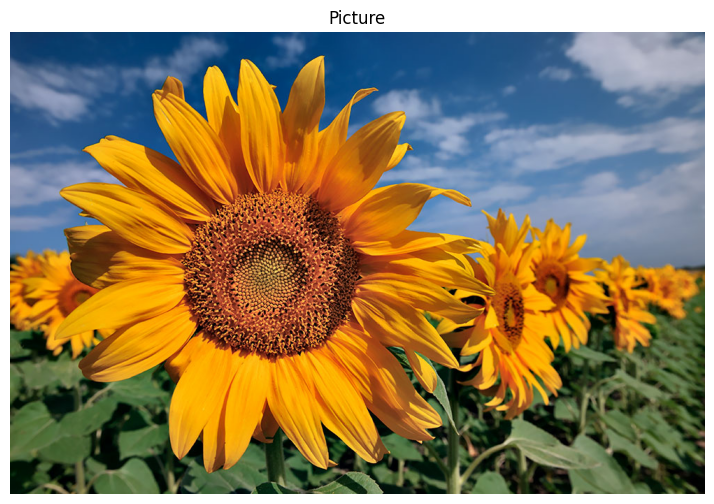

In [4]:
# Graphic results

import matplotlib.pyplot as plt

# Input data
data = img_rgb

# Solution
_, ax = plt.subplots(figsize=(9, 6))

ax.imshow(data)
ax.axis(False)

# Plot it
plt.title("Picture")
plt.show()


In [5]:
# Unsharp image -> GaussianBlur

import numpy as np

# Input data
amount = 3
# (0, 0) auto-adaptation of the kernel
ksize = (0, 0)
# 0 auto-adaptation of the sigma
sigmaX = 3

# Solution
# Create a blurred (unsharp) version of the original image (you can use Gaussian blurring)
unsharp = cv2.GaussianBlur(img_rgb, ksize=ksize, sigmaX=sigmaX)

# Create the difference image (original − unsharp)
# Note: Remember that you are working with uint8 data types. Any addition or substractions
# might result in overflow or underflow, respectively. You can prevent this by casting the images to float.
diff = img_rgb.astype(np.float32) - unsharp.astype(np.float32)
difference = np.abs(diff).astype(np.uint8)
# difference = np.clip(diff, 0, 255).astype(np.uint8)

# Apply USM to get the resulting image using `sharpened = original + (original − unsharp) × amount`
# Note: Again, take care of underflows/overflows if necessary.
sharpened = img_rgb.astype(np.float32) + amount * diff
sharpened = np.clip(sharpened, 0, 255).astype(np.uint8)

images_dict = {
    "original": img_rgb,
    "unsharp": unsharp,
    "difference": difference,
    "sharpened": sharpened,
}
# Print results

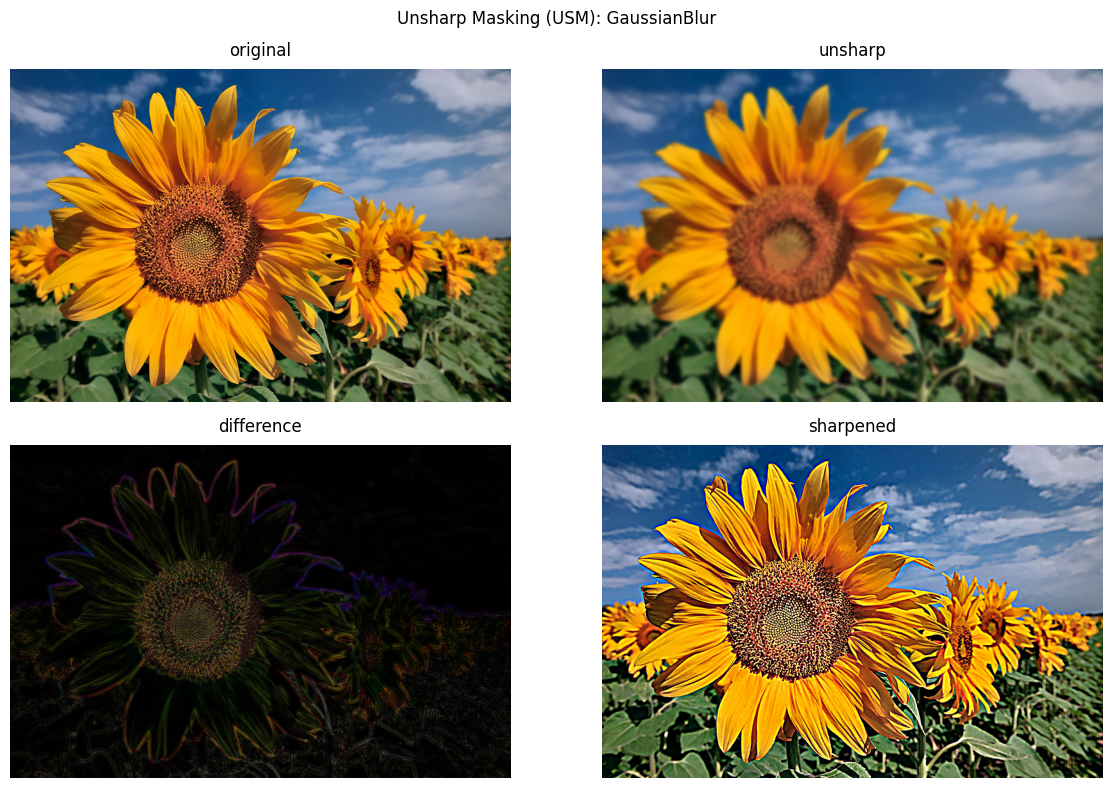

In [6]:
# Graphic results

import math
import matplotlib.pyplot as plt

# Input data
n_img_cols = 2
n_img_rows = math.ceil(len(images_dict) / n_img_cols)

# Solution
_, axes = plt.subplots(n_img_rows, n_img_cols, figsize=(12, 4 * n_img_rows))
axes_list = axes.flatten()

for idx, (img_name, img_data) in enumerate(images_dict.items()):
    ax = axes_list[idx]
    ax.set_title(img_name, pad=10, loc='center', color='black')
    ax.imshow(img_data)
    ax.axis(False)

# Plot
plt.suptitle("Unsharp Masking (USM): GaussianBlur")
plt.tight_layout()
plt.show()


In [7]:
# Unsharp image -> bilateralFilter

import numpy as np

# Input data
amount = 3
# 0 auto-adaptation of the kernel
d = -1
# 0 or -1 auto-adaptation of the sigma
sigmaColor = 75
sigmaSpace = 75

# Solution
# Create a blurred (unsharp) version of the original image (you can use Gaussian blurring)
unsharp = cv2.bilateralFilter(img_rgb, d=d, sigmaColor=sigmaColor, sigmaSpace=sigmaSpace)

# Create the difference image (original − unsharp)
# Note: Remember that you are working with uint8 data types. Any addition or substractions
# might result in overflow or underflow, respectively. You can prevent this by casting the images to float.
diff = img_rgb.astype(np.float32) - unsharp.astype(np.float32)
difference = np.abs(diff).astype(np.uint8)
# difference = np.clip(diff, 0, 255).astype(np.uint8)

# Apply USM to get the resulting image using `sharpened = original + (original − unsharp) × amount`
# Note: Again, take care of underflows/overflows if necessary.
sharpened = img_rgb.astype(np.float32) + amount * diff
sharpened = np.clip(sharpened, 0, 255).astype(np.uint8)

images_dict = {
    "original": img_rgb,
    "unsharp": unsharp,
    "difference": difference,
    "sharpened": sharpened,
}
# Print results

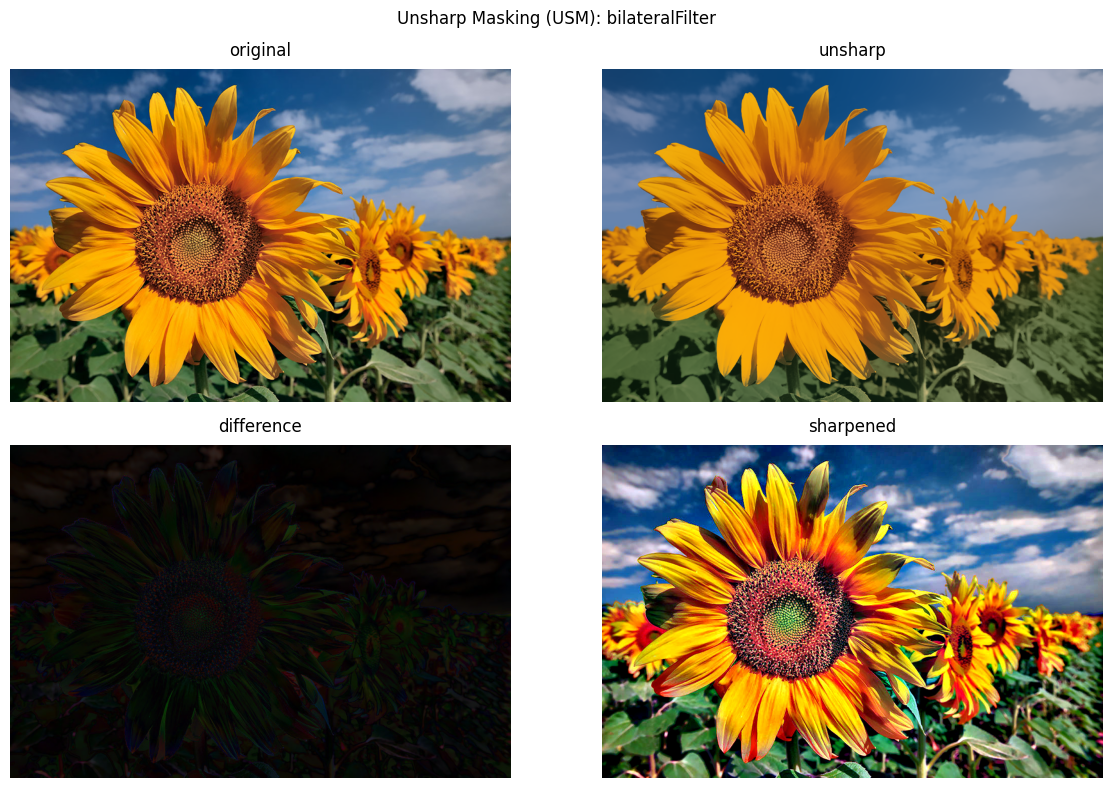

In [8]:
# Graphic results

import math
import matplotlib.pyplot as plt

# Input data
n_img_cols = 2
n_img_rows = math.ceil(len(images_dict) / n_img_cols)

# Solution
_, axes = plt.subplots(n_img_rows, n_img_cols, figsize=(12, 4 * n_img_rows))
axes_list = axes.flatten()

for idx, (img_name, img_data) in enumerate(images_dict.items()):
    ax = axes_list[idx]
    ax.set_title(img_name, pad=10, loc='center', color='black')
    ax.imshow(img_data)
    ax.axis(False)

# Plot
plt.suptitle("Unsharp Masking (USM): bilateralFilter")
plt.tight_layout()
plt.show()


In [9]:
# Unsharp image -> medianBlur

import numpy as np

# Input data
amount = 3
ksize = 5

# Solution
# Create a blurred (unsharp) version of the original image (you can use Gaussian blurring)
unsharp = cv2.medianBlur(img_rgb, ksize=ksize)

# Create the difference image (original − unsharp)
# Note: Remember that you are working with uint8 data types. Any addition or substractions
# might result in overflow or underflow, respectively. You can prevent this by casting the images to float.
diff = img_rgb.astype(np.float32) - unsharp.astype(np.float32)
difference = np.abs(diff).astype(np.uint8)
# difference = np.clip(diff, 0, 255).astype(np.uint8)

# Apply USM to get the resulting image using `sharpened = original + (original − unsharp) × amount`
# Note: Again, take care of underflows/overflows if necessary.
sharpened = img_rgb.astype(np.float32) + amount * diff
sharpened = np.clip(sharpened, 0, 255).astype(np.uint8)

images_dict = {
    "original": img_rgb,
    "unsharp": unsharp,
    "difference": difference,
    "sharpened": sharpened,
}
# Print results

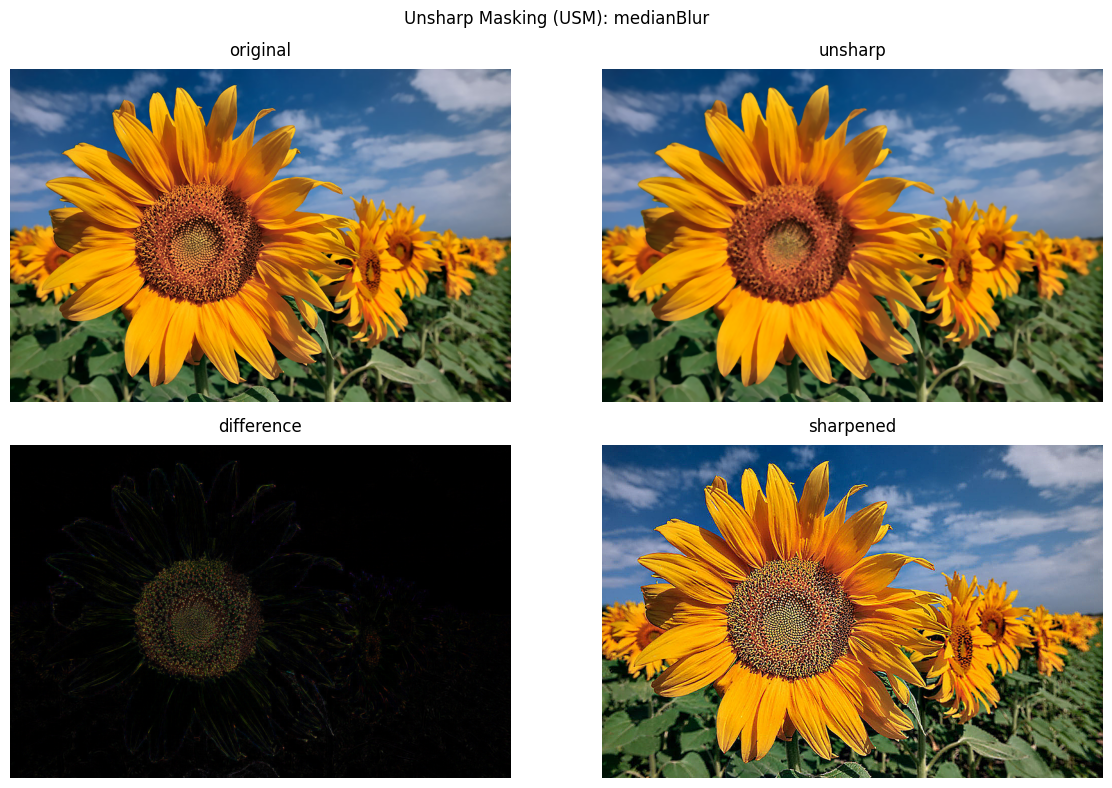

In [10]:
# Graphic results

import math
import matplotlib.pyplot as plt

# Input data
n_img_cols = 2
n_img_rows = math.ceil(len(images_dict) / n_img_cols)

# Solution
_, axes = plt.subplots(n_img_rows, n_img_cols, figsize=(12, 4 * n_img_rows))
axes_list = axes.flatten()

for idx, (img_name, img_data) in enumerate(images_dict.items()):
    ax = axes_list[idx]
    ax.set_title(img_name, pad=10, loc='center', color='black')
    ax.imshow(img_data)
    ax.axis(False)

# Plot
plt.suptitle("Unsharp Masking (USM): medianBlur")
plt.tight_layout()
plt.show()


### Questions
* What is a good (reasonable) value for the `amount` parameter?
* What happens if it is too small?
* What happens if it is too large?

## Conclusion

A reasonable value for the amount parameter depends on the image type: soft portraits require lower values to remain natural, while detailed landscapes benefit from higher settings. As the parameter value approaches zero, the effect of unsharp masking decreases to a minimum, leaving the image in its original soft state. Conversely, increasing the value makes the contours much more prominent, but setting it too high leads to overprocessing, creating harsh white halos around objects, amplifying digital noise, and destroying fine details.